# Notebook

In [1]:
import os, sys
env = sys.prefix
os.environ["PATH"] = os.path.join(env, "Library", "bin") + os.pathsep + os.environ["PATH"]
os.environ["GDAL_DATA"] = os.path.join(env, "Library", "share", "gdal")
os.environ["PROJ_DATA"] = os.path.join(env, "Library", "share", "proj")

import geopandas as gpd
import rasterio
print("ok")

ok


In [2]:
# import libraries
import rasterio
import geopandas as gpd
from shapely.geometry import Polygon
from rasterio.mask import mask
from pathlib import Path
import os
import ee
import geemap
from shapely.geometry import mapping
from dotenv import load_dotenv
import geoai

# import function 
from functions.merge_tifs import merge_tifs
from functions.clip_tifs import clip_tifs


c:\Users\lilsh\miniconda3\envs\sds320_new\Lib\site-packages\google\api_core\_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.82.2. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(


In [3]:
# Settings
load_dotenv()
ee.Initialize(project=os.getenv("EE_PROJECT_ID"))


In [4]:
# Set working folder
#os.chdir(r"C:/Users/lilsh/Dokumente/Studium/sds320/HS26_SDS320_SpatialDataAnalytics/project/")
#print("New Working Directory:", os.getcwd())

### Merging tifs

In [5]:
# the diffrent tifs
# the pre event tifs
rgb_pre_north = "../data/raw/raster/10300100E57BC400-visual_pre_north.tif"
rgb_pre_south = "../data/raw/raster/10300100E57BC400-visual_pre_south.tif"
ms_pre_north = "../data/raw/raster/10300100E57BC400-ms_pre_north.tif"
ms_pre_south = "../data/raw/raster/10300100E57BC400-ms_pre_south.tif"
pan_pre_north = "../data/raw/raster/10300100E57BC400-pan_pre_north.tif"
pan_pre_south = "../data/raw/raster/10300100E57BC400-pan_pre_south.tif"

# the post event tifs
rgb_post_north = "../data/raw/raster/1040010084614200-visual_post_north.tif"
rgb_post_south = "../data/raw/raster/1040010084614200-visual_post_south.tif"
ms_post_north = "../data/raw/raster/1040010084614200-ms_post_north.tif"
ms_post_south = "../data/raw/raster/1040010084614200-ms_post_south.tif"
pan_post_north = "../data/raw/raster/1040010084614200-pan_post_north.tif"
pan_post_south = "../data/raw/raster/1040010084614200-pan_post_south.tif"


In [6]:
# combine the tifs
rgb_pre = merge_tifs([rgb_pre_north, rgb_pre_south], "../data/processed/rgb_pre.tif")
ms_pre = merge_tifs([ms_pre_north, ms_pre_south], "../data/processed/ms_pre.tif")
pan_pre = merge_tifs([pan_pre_north, pan_pre_south], "../data/processed/pan_pre.tif")

rgb_post = merge_tifs([rgb_post_north, rgb_post_south], "../data/processed/rgb_post.tif")
ms_post = merge_tifs([ms_post_north, ms_post_south], "../data/processed/ms_post.tif")
pan_post = merge_tifs([pan_post_north, pan_post_south], "../data/processed/pan_post.tif")

Skipping (already exists): ..\data\processed\rgb_pre.tif
Skipping (already exists): ..\data\processed\ms_pre.tif
Skipping (already exists): ..\data\processed\pan_pre.tif
Skipping (already exists): ..\data\processed\rgb_post.tif
Skipping (already exists): ..\data\processed\ms_post.tif
Skipping (already exists): ..\data\processed\pan_post.tif


In [7]:
# inspect the merged tifs
with rasterio.open("../data/processed/rgb_pre.tif") as src:
    print("rgb pre:")
    print(src.width, src.height, src.count, src.dtypes[0])
    print(src.crs, src.res, src.bounds, src.nodata)
    print(src.tags(ns="ImageStructure"))
    print("\n")

with rasterio.open("../data/processed/ms_pre.tif") as src:
    print("ms pre:")
    print(src.width, src.height, src.count, src.dtypes[0])
    print(src.crs, src.res, src.bounds, src.nodata)
    print(src.tags(ns="ImageStructure"))
    print("\n")

with rasterio.open("../data/processed/pan_pre.tif") as src:
    print("pan pre:")
    print(src.width, src.height, src.count, src.dtypes[0])
    print(src.crs, src.res, src.bounds, src.nodata)
    print(src.tags(ns="ImageStructure"))
    print("\n")

with rasterio.open("../data/processed/rgb_post.tif") as src:
    print("rgb post:")
    print(src.width, src.height, src.count, src.dtypes[0])
    print(src.crs, src.res, src.bounds, src.nodata)
    print(src.tags(ns="ImageStructure"))
    print("\n")

with rasterio.open("../data/processed/ms_post.tif") as src:
    print("ms post:")
    print(src.width, src.height, src.count, src.dtypes[0])
    print(src.crs, src.res, src.bounds, src.nodata)
    print(src.tags(ns="ImageStructure"))
    print("\n")

with rasterio.open("../data/processed/pan_post.tif") as src:
    print("pan post:")
    print(src.width, src.height, src.count, src.dtypes[0])
    print(src.crs, src.res, src.bounds, src.nodata)
    print(src.tags(ns="ImageStructure"))
    print("\n")

rgb pre:
17408 33792 3 uint8
EPSG:32735 (0.30517578125, 0.30517578125) BoundingBox(left=709843.75, bottom=9774843.75, right=715156.25, top=9785156.25) None
{}


ms pre:
2795 5426 8 uint16
EPSG:32735 (1.9007155635062611, 1.9007155635062611) BoundingBox(left=709843.75, bottom=9774842.967352415, right=715156.25, top=9785156.25) None
{}


pan pre:
11180 21702 1 uint16
EPSG:32735 (0.4751788908765653, 0.4751788908765653) BoundingBox(left=709843.75, bottom=9774843.917710196, right=715156.25, top=9785156.25) None
{}


rgb post:
17408 33792 3 uint8
EPSG:32735 (0.30517578125, 0.30517578125) BoundingBox(left=709843.75, bottom=9774843.75, right=715156.25, top=9785156.25) None
{}


ms post:
3732 7244 8 uint16
EPSG:32735 (1.4234994640943195, 1.4234994640943195) BoundingBox(left=709843.75, bottom=9774844.4198821, right=715156.25, top=9785156.25) None
{}


pan post:
14928 28978 1 uint16
EPSG:32735 (0.35587486602357987, 0.35587486602357987) BoundingBox(left=709843.75, bottom=9774843.70813237, right=715

---
### Select AOI

Select AOI for training, validation and test areas. The AOIs were drawn on QGIS as polygons.

In [8]:
# select training, validatation and test areas polygons
aoi_training = gpd.read_file("../GIS/aoi_training.gpkg")
aoi_validation = gpd.read_file("../GIS/aoi_validation.gpkg")
aoi_test = gpd.read_file("../GIS/aoi_test.gpkg")
aoi_prototype = gpd.read_file("../GIS/aoi_prototype.gpkg")

print(aoi_training.crs)
src = rasterio.open("../data/processed/ms_post.tif")
print(src.crs, src.shape)

EPSG:32735
EPSG:32735 (7244, 3732)


---
### Clip AOI

In [9]:
tif_names = ["ms_post.tif", "ms_pre.tif", "pan_post.tif",
             "pan_pre.tif", "rgb_post.tif", "rgb_pre.tif"]

# clip training data aoi
clip_tifs(
    tif_names,
    aoi_path="../GIS/aoi_training.gpkg",
    folder="../data/processed",
    suffix="_training"
)

# clip validation data aoi
clip_tifs(
    tif_names,
    aoi_path="../GIS/aoi_validation.gpkg",
    folder="../data/processed",
    suffix="_validation"
)

# clip test data aoi
clip_tifs(
    tif_names,
    aoi_path="../GIS/aoi_test.gpkg",
    folder="../data/processed",
    suffix="_test"
)

clip_tifs(
    tif_names,
    aoi_path="../GIS/aoi_prototype.gpkg",
    folder="../data/processed",
    suffix="_prototype"
)


skipping (already exists): ms_post_training.tif
skipping (already exists): ms_pre_training.tif
skipping (already exists): pan_post_training.tif
skipping (already exists): pan_pre_training.tif
skipping (already exists): rgb_post_training.tif
skipping (already exists): rgb_pre_training.tif
skipping (already exists): ms_post_validation.tif
skipping (already exists): ms_pre_validation.tif
skipping (already exists): pan_post_validation.tif
skipping (already exists): pan_pre_validation.tif
skipping (already exists): rgb_post_validation.tif
skipping (already exists): rgb_pre_validation.tif
skipping (already exists): ms_post_test.tif
skipping (already exists): ms_pre_test.tif
skipping (already exists): pan_post_test.tif
skipping (already exists): pan_pre_test.tif
skipping (already exists): rgb_post_test.tif
skipping (already exists): rgb_pre_test.tif
clipping ms_post.tif
clipping ms_pre.tif
clipping pan_post.tif
clipping pan_pre.tif
clipping rgb_post.tif
clipping rgb_pre.tif


[WindowsPath('../data/processed/ms_post_prototype.tif'),
 WindowsPath('../data/processed/ms_pre_prototype.tif'),
 WindowsPath('../data/processed/pan_post_prototype.tif'),
 WindowsPath('../data/processed/pan_pre_prototype.tif'),
 WindowsPath('../data/processed/rgb_post_prototype.tif'),
 WindowsPath('../data/processed/rgb_pre_prototype.tif')]

## Set up Google Earth Engine

In [10]:
# check the aois crs
print(aoi_training.crs, aoi_training.area)
print(aoi_validation.crs, aoi_validation.area)
print(aoi_test.crs, aoi_test.area)
print(aoi_prototype.crs, aoi_prototype.area)

EPSG:32735 0    929403.194083
dtype: float64
EPSG:32735 0    157823.470364
dtype: float64
EPSG:32735 0    288568.11078
dtype: float64
EPSG:32735 0    21938.92468
dtype: float64


In [11]:
# combine the aois
aoi_ee = {
    "train": aoi_training,
    "val":   aoi_validation,
    "test":  aoi_test,
    "prototype": aoi_prototype
} 

OB = ee.FeatureCollection("GOOGLE/Research/open-buildings/v3/polygons")
results = {}

for name, aoi in aoi_ee.items():
    # reproject to lon/lat for Earth Engine only
    aoi_ll = aoi.to_crs(4326)
    geom_ee = ee.Geometry(mapping(aoi_ll.union_all()), proj="EPSG:4326", geodesic=False)

    fc = (OB.filterBounds(geom_ee)
            .filter(ee.Filter.gte("confidence", 0.7)))   # threshold confidence level

    n = fc.size().getInfo()
    print(f"{name}: {n} buildings")

    if n == 0:
        continue
    if n > 5000:
        print(f"  -> {name} is large, use the Drive export below")
        continue

    gdf = geemap.ee_to_gdf(fc)
    if gdf.crs is None:
        gdf = gdf.set_crs("EPSG:4326")
    gdf = gdf.to_crs(32735)

    # keep only the parts inside this AOI
    gdf = gpd.overlay(gdf, aoi[["geometry"]], how="intersection")
    gdf["split"] = name
    gdf["area_m2"] = gdf.geometry.area

    gdf.to_file(f"../data/processed/buildings_{name}.gpkg", driver="GPKG")
    results[name] = gdf



train: 856 buildings
val: 321 buildings
test: 401 buildings
prototype: 83 buildings


In [8]:
# Inspecting the Engine data and the satelite data
m = geemap.Map(ee_initialize=False)   # if it complains about Earth Engine, use geemap.Map(ee_initialize=False)
m.add_raster("../data/processed/rgb_pre_training.tif", layer_name="RGB_pre")
m.add_raster("../data/processed/rgb_post_training.tif", layer_name="RGB_post")
m.add_vector("../data/processed/buildings_train.gpkg", layer_name="Buildings",
             style={"color": "red", "fillOpacity": 0})
m

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

Note that there is a small offset between the data from Google Earth Engine and the visual image. Shift approximatly 2 meters south and 4 meters west

In [17]:
from rasterio.transform import Affine

dx, dy = -3, -2.1   # metres: positive dx = move east, positive dy = move north

src_path = "../data/processed/rgb_pre_training.tif"
dst_path = "../data/processed/rgb_pre_training_shifted.tif"

with rasterio.open(src_path) as src:
    profile = src.profile.copy()
    data = src.read()
    t = src.transform

# a = pixel width, b = row rotation, c = x origin (west edge)
# d = column rotation, e = pixel height (negative), f = y origin (north edge)
profile["transform"] = Affine(t.a, t.b, t.c + dx,
                              t.d, t.e, t.f + dy)

with rasterio.open(dst_path, "w", **profile) as dst:
    dst.write(data)

In [18]:
# Re-evalute after the shift
m = geemap.Map(ee_initialize=False)   # if it complains about Earth Engine, use geemap.Map(ee_initialize=False)
m.add_raster("../data/processed/rgb_pre_training_shifted.tif", layer_name="RGB_pre")
m.add_raster("../data/processed/rgb_post_training.tif", layer_name="RGB_post")
m.add_vector("../data/processed/buildings_train.gpkg", layer_name="Buildings",
             style={"color": "red", "fillOpacity": 0})
m

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

## Prototype

In [3]:
# Check geoai
import sys, geoai
from importlib.metadata import version
print(sys.executable)
print(version("geoai-py"))
print(geoai.__file__)

c:\Users\lilsh\miniconda3\envs\sds320_new\python.exe
0.36.0
c:\Users\lilsh\miniconda3\envs\sds320_new\Lib\site-packages\geoai\__init__.py


In [27]:
# shift pre image
from rasterio.transform import Affine

dx, dy = -3, -2.1   # metres: positive dx = move east, positive dy = move north

src_path = "../data/processed/rgb_pre_prototype.tif"
dst_path = "../data/processed/rgb_pre_prototype_shifted.tif"

with rasterio.open(src_path) as src:
    profile = src.profile.copy()
    data = src.read()
    t = src.transform

# a = pixel width, b = row rotation, c = x origin (west edge)
# d = column rotation, e = pixel height (negative), f = y origin (north edge)
profile["transform"] = Affine(t.a, t.b, t.c + dx,
                              t.d, t.e, t.f + dy)

with rasterio.open(dst_path, "w", **profile) as dst:
    dst.write(data)

In [ ]:
# Transfer reference data from vector to raster
geoai.vector_to_raster(
    "../data/processed/buildings_prototype.gpkg",
    "../data/processed/buildings_prototype.tif",
    reference_raster = "../data/processed/rgb_pre_prototype.tif"
)


array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(671, 703), dtype=uint8)

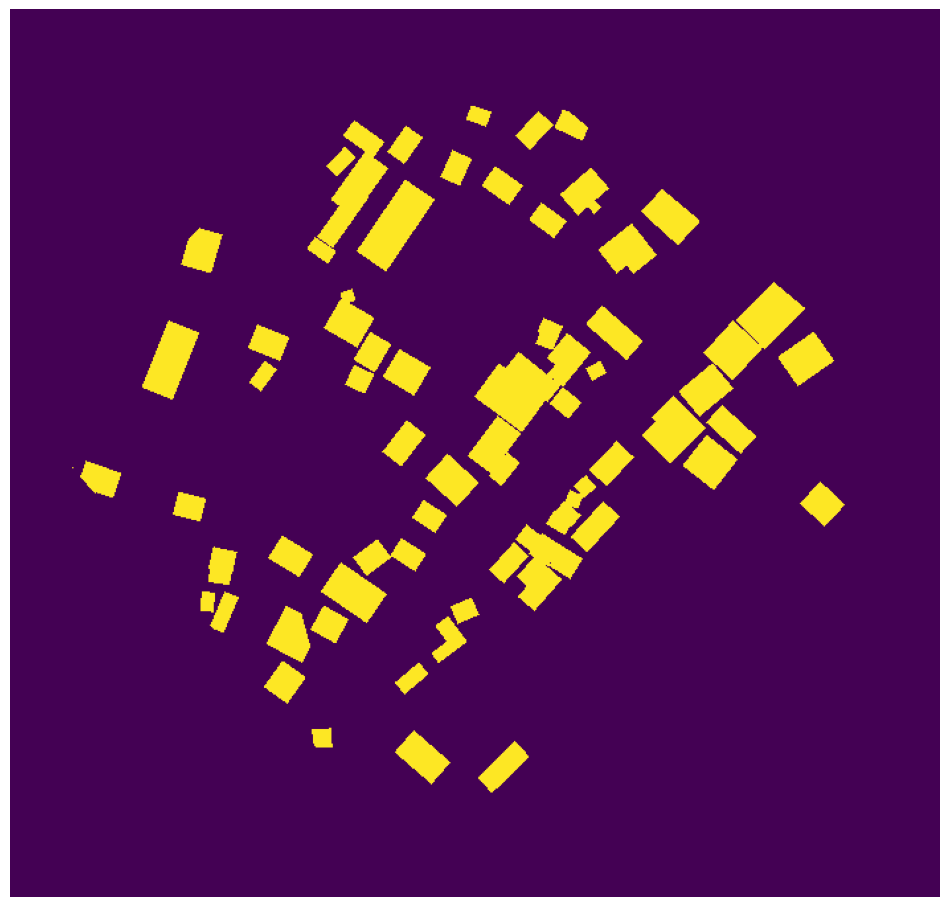

In [4]:
geoai.view_image("../data/processed/buildings_prototype.tif", figsize=(12,12))

In [10]:
# Tiling into chips
import matplotlib.cm as cm
import matplotlib.pyplot as plt

if not hasattr(cm, "get_cmap"):
    cm.get_cmap = plt.get_cmap

tiles = geoai.export_geotiff_tiles(
    in_raster="../data/processed/rgb_pre_prototype_shifted.tif",
    out_folder="../data/prototype",
    in_class_data="../data/processed/buildings_prototype.gpkg",
    tile_size=256,
    stride=192,
    buffer_radius=0,
    skip_empty_tiles=True,
    create_overview=True,
    quiet=True,
)


Generated: 15, With features: 15: 100%|██████████| 16/16 [00:00<00:00, 19.17it/s]


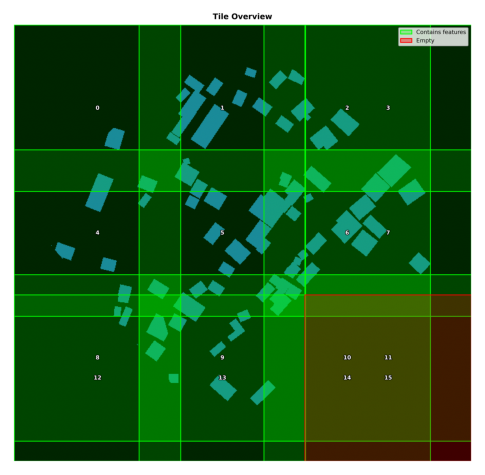

In [31]:
geoai.view_image("../data/prototype/overview.png", figsize=(6, 6))

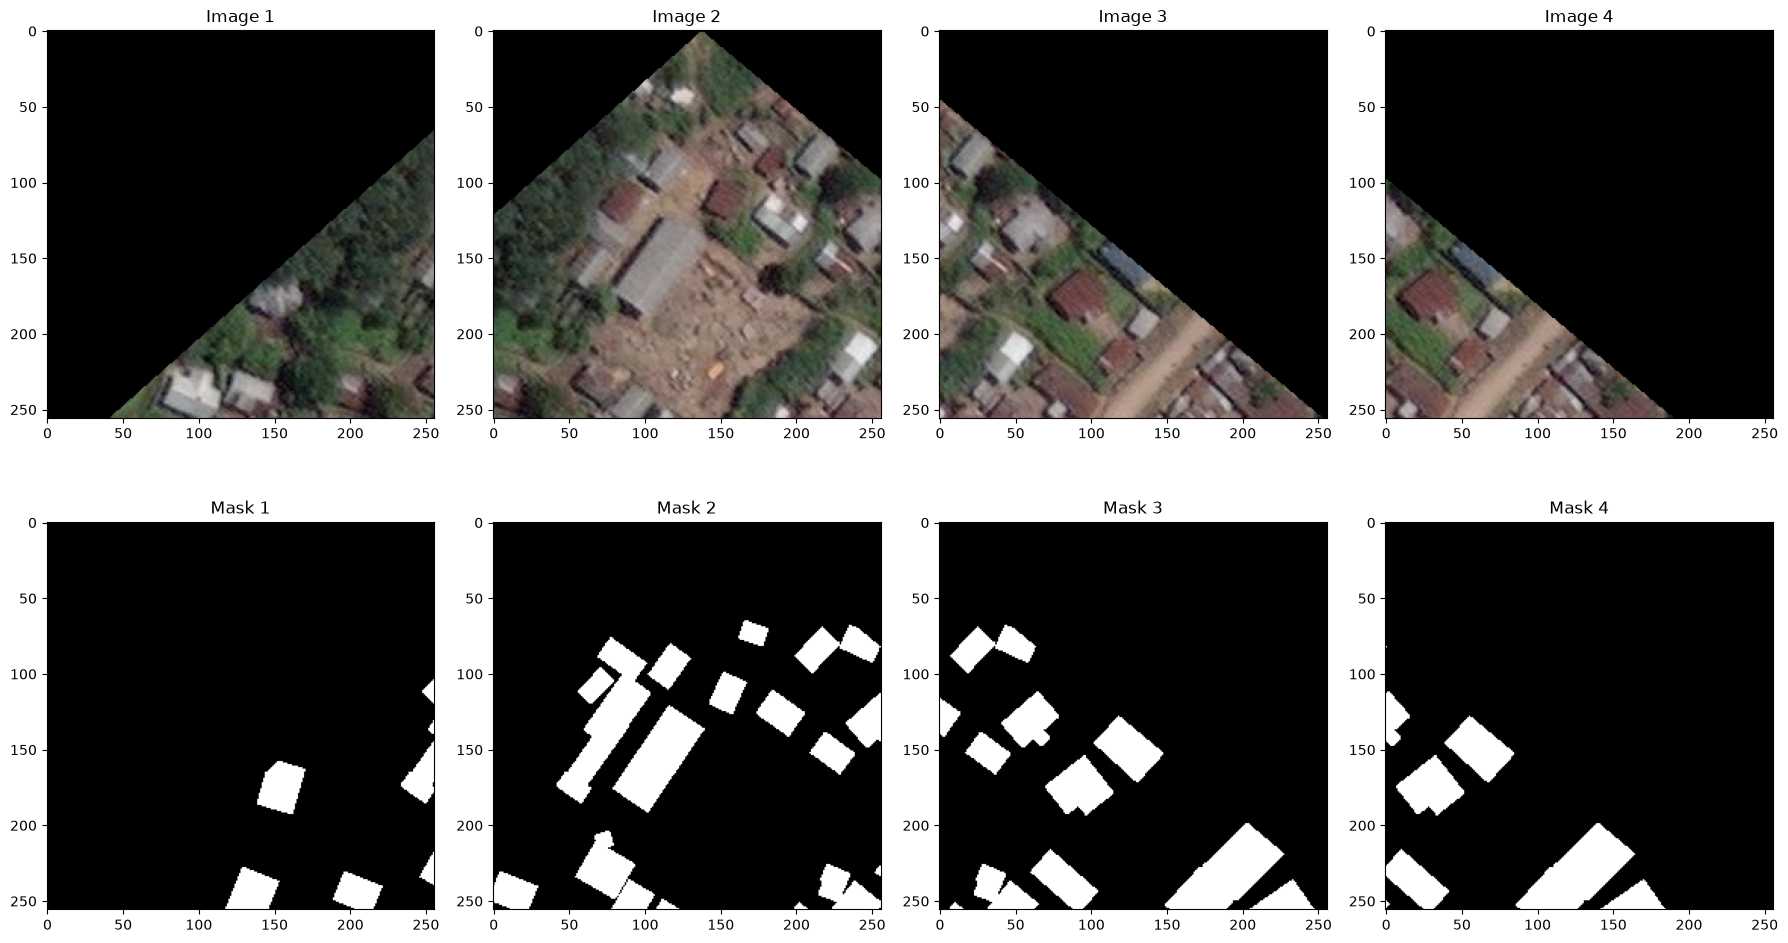

In [32]:
fig = geoai.display_training_tiles(
    output_dir="../data/prototype",
    num_tiles=4,
    figsize=(18, 10),
)

### batch and pairing

In [5]:
from shapely.geometry import box
from pathlib import Path


data_dir = Path("../data/prototype")
img_dir = data_dir / "images"
mask_dir = data_dir / "masks"
mask_dir.mkdir(parents=True, exist_ok=True)

buildings = gpd.read_file("../data/processed/buildings_prototype.gpkg")

for img_path in sorted(img_dir.glob("*.tif")):
    with rasterio.open(img_path) as src:
        tile_box = box(*src.bounds)
        tile_crs = src.crs

    tile_buildings = buildings.to_crs(tile_crs)
    tile_buildings = tile_buildings[tile_buildings.intersects(tile_box)]

    # cut polygons at the tile edge
    tile_buildings = gpd.clip(tile_buildings, tile_box)
    tile_buildings = tile_buildings[
        ~tile_buildings.is_empty & tile_buildings.geom_type.isin(["Polygon", "MultiPolygon"])
    ]

    tile_buildings.to_file(mask_dir / f"{img_path.stem}.geojson", driver="GeoJSON")

print(len(list(mask_dir.glob("*.geojson"))), "mask files written")

15 mask files written


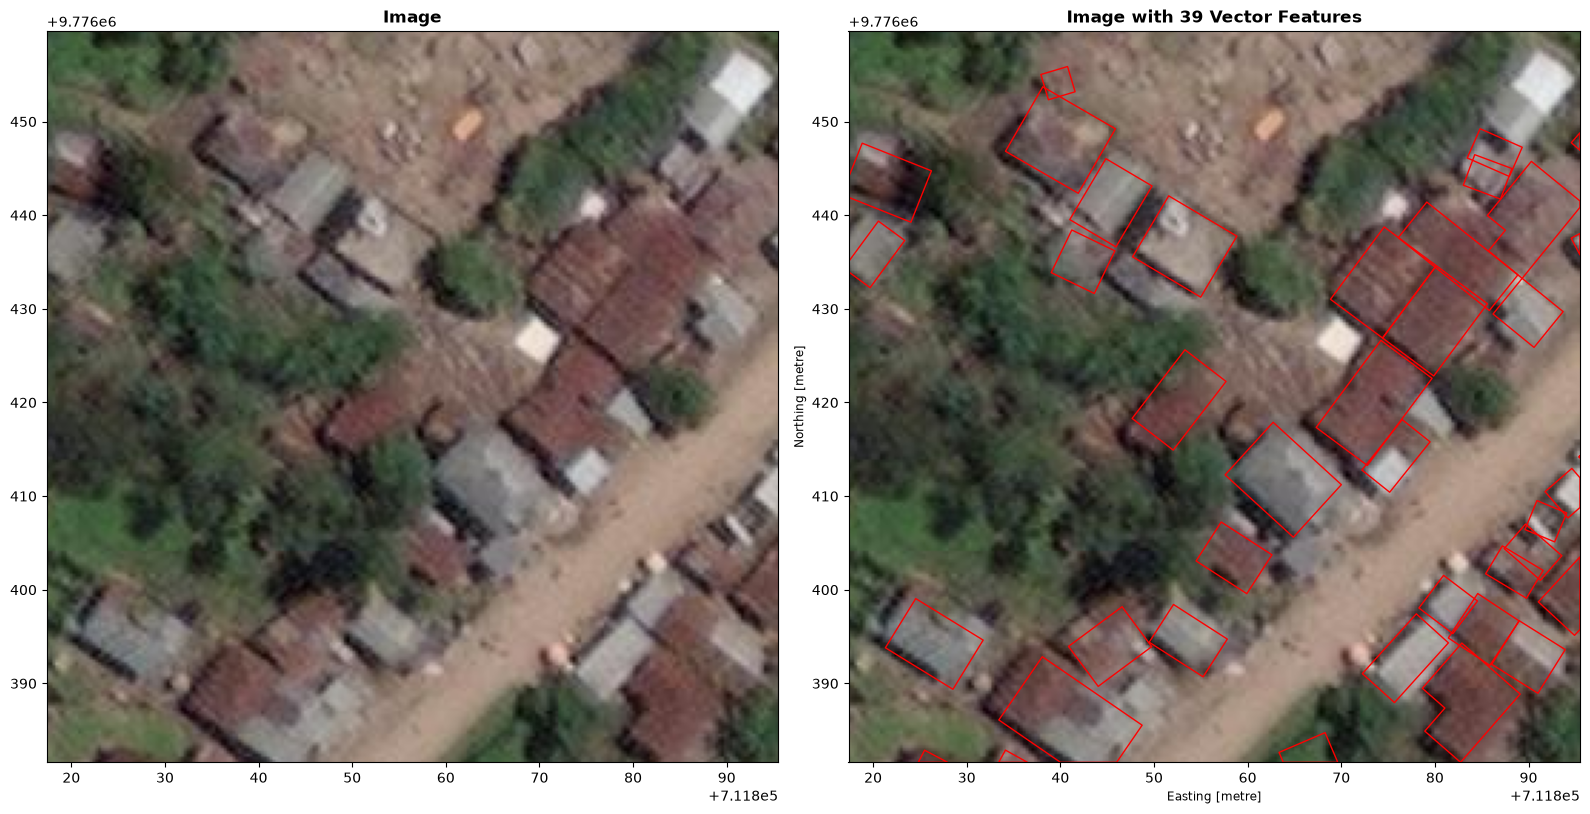

Number of buildings: 39


In [13]:
image_path = "../data/prototype/images/tile_000005.tif"
mask_path = "../data/prototype/masks/tile_000005.geojson"

fig, axes, info = geoai.display_image_with_vector(image_path, mask_path)
print(f"Number of buildings: {info['num_features']}")

In [7]:
stats = geoai.export_geotiff_tiles_batch(
    images_folder=f"{data_dir}/images",
    masks_folder=f"{data_dir}/masks",
    output_folder="../data/prototype/matched_files",
    tile_size=256,
    stride=128,
    class_value_field="class",
    skip_empty_tiles=True,
    match_by_name=True,
)
print(f"Images processed: {stats['processed_pairs']}")
print(f"Total tiles generated: {stats['total_tiles']}")
print(f"Tiles with features: {stats['tiles_with_features']}")

Processing image pairs: 100%|██████████| 15/15 [00:01<00:00, 11.59it/s]

Images processed: 15
Total tiles generated: 15
Tiles with features: 15


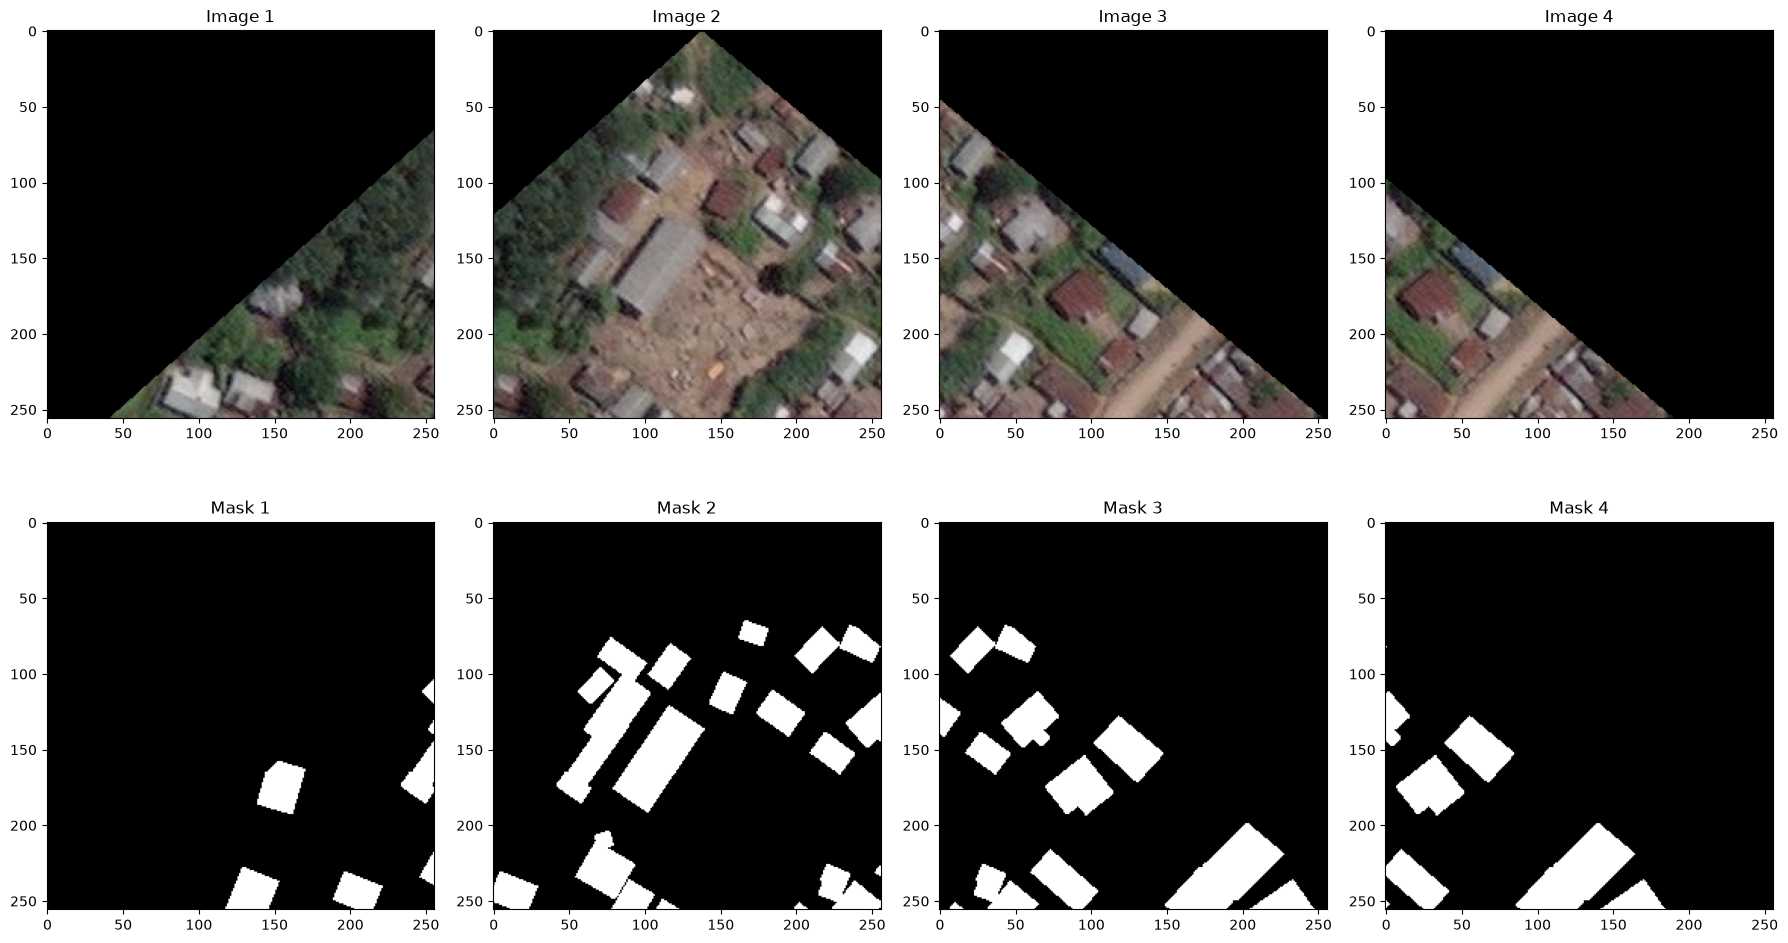

In [12]:
# visulaize generated patches

output_dir = "../data/prototype/matched_files"

fig = geoai.display_training_tiles(
    output_dir=output_dir,
    num_tiles=4,
    figsize=(18, 10),
)

#### Prepere prototype for training

In [ ]:
prepared_dir = Path(data["images_dir"]).parent

geoai.display_training_tiles(
    output_dir=str(prepared_dir),
    num_tiles=4,
    figsize=(12, 6),
    cmap="tab20",
)

FileNotFoundError: Country directory not found: ../data/prototype\luxembourg. Run download_ftw(countries=['luxembourg'], output_dir='../data/prototype') first.